# 01 · Data profiling & data-quality audit

**Goal:** understand the raw data before modelling it, and find every issue that
would bias the funnel, cohort or LTV numbers if left untreated.

For each issue: **detect → explain why it matters → decide → document.** Nothing is
cleaned in this notebook; the decisions are implemented in the staging SQL layer
(`sql/staging/`) and summarised in `docs/data_quality_report.md`.

> Dataset: synthetic, generated by `src/generate_data.py` for the fictional brand
> "Threadline". The analyst workflow below is the same one you would use on real data.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from db import query as q
import viz

viz.setup()

## 1. Inventory: tables, rows, grain

In [2]:
q("""
select 'events' as table_name, count(*) as row_count, count(distinct event_id) as distinct_pk from raw.events
union all select 'orders', count(*), count(distinct order_id) from raw.orders
union all select 'order_items', count(*), count(distinct order_item_id) from raw.order_items
union all select 'users', count(*), count(distinct user_id) from raw.users
union all select 'products', count(*), count(distinct product_id) from raw.products
union all select 'marketing_spend', count(*), count(distinct (date, platform, campaign_type)) from raw.marketing_spend
""")

,table_name,row_count,distinct_pk
0,events,3987538,3971667
1,orders,33748,33658
2,order_items,52130,52130
3,users,53212,53212
4,products,480,480
5,marketing_spend,5086,5086


**Finding:** `events` and `orders` have more rows than distinct primary keys → duplicates (section 3).

## 2. Missing values

In [3]:
q("""
select
  round(100 * avg((user_id is null)::int), 1)          as pct_user_id_null,
  round(100 * avg((device_type is null)::int), 1)      as pct_device_null,
  round(100 * avg((utm_source is null)::int), 1)       as pct_utm_source_null,
  round(100 * avg((utm_source is not null and utm_medium is null)::int), 2) as pct_source_without_medium,
  round(100 * avg((referrer_domain is null)::int), 1)  as pct_referrer_null,
  round(100 * avg((event_name in ('product_view','add_to_cart') and product_id is null)::int), 2) as pct_product_event_wo_product,
  round(100 * avg((event_name = 'purchase' and order_id is null)::int), 3) as pct_purchase_wo_order_id
from raw.events
""")

,pct_user_id_null,pct_device_null,pct_utm_source_null,pct_source_without_medium,pct_referrer_null,pct_product_event_wo_product,pct_purchase_wo_order_id
0,92.4,0.0,45.1,1.49,65.3,0.0,0.0


In [4]:
q("""
select
  sum((user_id is null)::int) as orders_without_user,
  sum((lower(status) = 'delivered' and delivered_at is null)::int) as delivered_without_date,
  sum((lower(status) = 'cancelled' and cancelled_at is null)::int) as cancelled_without_date,
  sum((discount_code is null)::int) as orders_without_discount_code
from raw.orders
""")

,orders_without_user,delivered_without_date,cancelled_without_date,orders_without_discount_code
0,0,0,3,24823


`user_id` is null on most events. That is **expected**: visitors are anonymous until they
register or log in. To attribute a customer's first visit (their acquisition channel)
we need **identity stitching**: map `visitor_id → user_id` from any event that carries both,
then apply that user to the visitor's earlier anonymous sessions.

In [5]:
q("""
with m as (select visitor_id, count(distinct user_id) as n_users
           from raw.events where user_id is not null group by 1)
select n_users as users_per_visitor, count(*) as visitors from m group by 1 order by 1
""")

,users_per_visitor,visitors
0,1,37921


Each visitor maps to exactly one user, so stitching is unambiguous (in real data you would
often see shared devices mapping to several users and need a tie-break rule).

## 3. Duplicates

In [6]:
q("""
with exact as (
  select event_id, count(*) as n from raw.events group by 1 having count(*) > 1
), natural_key as (
  select session_id, event_name, event_ts_utc, coalesce(product_id, -1) as p, coalesce(order_id, -1) as o,
         count(*) as n, count(distinct event_id) as ids
  from raw.events group by all having count(*) > 1 and count(distinct event_id) > 1
)
select (select count(*) from exact) as event_ids_duplicated,
       (select sum(n - 1) from exact) as extra_rows_same_event_id,
       (select sum(n - 1) from natural_key) as extra_rows_same_content_new_id
""")

,event_ids_duplicated,extra_rows_same_event_id,extra_rows_same_content_new_id
0,15871,15871,3979


In [7]:
q("""
select count(*) as duplicated_order_ids,
       sum(n - 1) as extra_rows,
       sum(identical::int) as fully_identical_rows
from (select order_id, count(*) as n, count(distinct (order_id, user_id, created_at, status, order_total)) = 1 as identical
      from raw.orders group by 1 having count(*) > 1)
""")

,duplicated_order_ids,extra_rows,fully_identical_rows
0,90,90,90


**Why it matters:** duplicate purchase events inflate conversion, and duplicate order rows
double-count revenue. **Decision:** dedupe events on `event_id`, then on the natural key
(session, event, timestamp, product, order). Dedupe orders on `order_id` (rows are fully identical).

## 4. Categorical consistency: status, UTM values

In [8]:
q("select status, count(*) as orders from raw.orders group by 1 order by 2 desc")

,status,orders
0,delivered,28757
1,rto,2982
2,cancelled,1415
3,DELIVERED,286
4,shipped,191
5,processing,70
6,RTO,33
7,CANCELLED,13
8,PROCESSING,1


In [9]:
q("""
select utm_source, utm_medium, count(distinct session_id) as sessions
from raw.events where utm_source is not null
group by 1, 2 order by 3 desc
""")

,utm_source,utm_medium,sessions
0,google,cpc,149144
1,instagram,paid_social,125574
2,facebook,paid_social,83740
3,cashback_site,affiliate,29481
4,newsletter,email,28169
5,instagram,paid,27149
6,fb,paid_social,22324
7,coupon_site,affiliate,20630
8,ig,paid_social,19358
9,klaviyo,email,19046


In [10]:
q("""
select referrer_domain, count(distinct session_id) as sessions
from raw.events where utm_source is null
group by 1 order by 2 desc
""")

,referrer_domain,sessions
0,google.com,201407
1,NaN,176663
2,bing.com,15645
3,l.instagram.com,12037
4,instagram.com,11925
5,duckduckgo.com,6747
6,youtube.com,6097
7,m.facebook.com,5932
8,stylemag.in,5930
9,pinterest.com,5794


**Findings:**
- Order status has mixed casing (`delivered` vs `DELIVERED`) from a legacy admin tool → normalise with `lower()`.
- Raw tracking has **no channel column**. The channel must be derived from `utm_source`, `utm_medium` and
  `referrer_domain`, and the values are messy: `facebook / fb / Facebook / ig`, `cpc / CPC / ppc`,
  `email / Email / e-mail`, and Meta traffic with `cpc` as medium (which a naive "medium = cpc → Paid Search" rule
  would misclassify) or with **no medium at all**.
- Instagram/Facebook referrers **without** UTMs are organic social posts, not paid ads.

**Decision:** a documented, ordered channel-grouping rule in `stg_sessions` (source first, then medium,
then referrer, else Direct), tested so that every session lands in exactly one channel.

## 5. Timestamps: ranges, time zones, clock skew

In [11]:
q("""
select 'events (utc text)' as source, min(event_ts_utc) as min_ts, max(event_ts_utc) as max_ts from raw.events
union all select 'orders.created_at', min(created_at)::varchar, max(created_at)::varchar from raw.orders
union all select 'users.created_at', min(created_at)::varchar, max(created_at)::varchar from raw.users
union all select 'marketing_spend.date', min(date)::varchar, max(date)::varchar from raw.marketing_spend
""")

,source,min_ts,max_ts
0,events (utc text),2023-12-31T18:33:11.000Z,2027-10-31T04:20:31.663Z
1,orders.created_at,2024-01-01 01:04:05,2026-09-30 23:56:26
2,users.created_at,2024-01-01 00:16:20,2026-09-30 23:53:36
3,marketing_spend.date,2024-01-01,2026-09-30


In [12]:
q("""
select count(*) as events_after_snapshot, count(distinct session_id) as sessions_affected
from raw.events where strptime(event_ts_utc, '%Y-%m-%dT%H:%M:%S.%gZ') > timestamp '2026-09-30 23:59:59'
""")

,events_after_snapshot,sessions_affected
0,27,27


In [13]:
tz = q("""
select date_diff('second', strptime(e.event_ts_utc, '%Y-%m-%dT%H:%M:%S.%gZ'), o.created_at) / 3600.0 as hours_order_minus_event
from raw.events e join (select distinct order_id, created_at from raw.orders) o using (order_id)
where e.event_name = 'purchase'
""")
tz.hours_order_minus_event.round(2).value_counts().head(5).rename("purchase_events")

,purchase_events
hours_order_minus_event,
5.5,32182


**Finding:** the order timestamp is consistently **5.5 hours later** than its purchase event, which is
exactly the IST (UTC+5:30) offset. The event pipeline logs in **UTC**, while the orders database stores
**local India time**. Mixing them would shift late-night orders into the wrong day and month, which
breaks daily funnels and month-boundary cohorts.

**Decision:** convert events to IST in staging (`event_ts_utc + 5h30m`) so that all reporting uses one
business time zone. Events dated after the snapshot (clock skew on a few devices) are excluded.

## 6. Bots and abnormal sessions

In [14]:
sess = q("""
select session_id, any_value(browser) as browser, count(*) as n_events,
       date_diff('second', min(strptime(event_ts_utc, '%Y-%m-%dT%H:%M:%S.%gZ')),
                           max(strptime(event_ts_utc, '%Y-%m-%dT%H:%M:%S.%gZ'))) as duration_s
from raw.events group by 1
""")
sess["events_per_min"] = sess.n_events / (sess.duration_s.clip(lower=1) / 60)
sess.n_events.describe(percentiles=[.5, .9, .99, .999]).round(1)

,n_events
count,1143609.0
mean,3.5
std,4.6
min,1.0
50%,3.0
90%,6.0
99%,9.0
99.9%,90.0
max,122.0


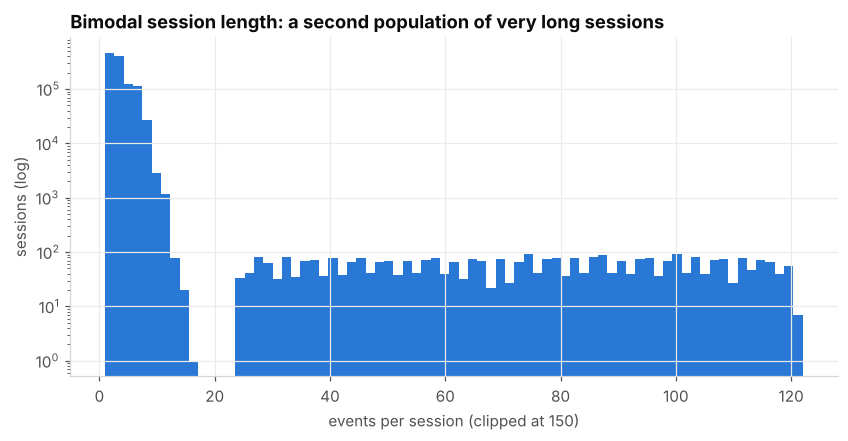

Text(0.0, 1.0, 'Bimodal session length: a second population of very long sessions')

In [15]:
fig, ax = plt.subplots()
ax.hist(sess.n_events.clip(upper=150), bins=75, color=viz.BLUE)
ax.set_yscale("log"); ax.set_xlabel("events per session (clipped at 150)"); ax.set_ylabel("sessions (log)")
ax.set_title("Bimodal session length: a second population of very long sessions")

In [16]:
sess.assign(is_long=sess.n_events >= 25).groupby("is_long").agg(
    sessions=("session_id", "count"), median_events=("n_events", "median"),
    median_events_per_min=("events_per_min", "median"),
    share_headless=("browser", lambda s: (s == "HeadlessChrome").mean())).round(2)

,sessions,median_events,median_events_per_min,share_headless
is_long,,,,
False,1140053,3.0,2.53,0.00
True,3556,74.0,55.65,0.41


**Finding:** a separate population of sessions with 25+ events at roughly 40 events per minute
(one page every 1–2 seconds), desktop only, with some identifying as `HeadlessChrome`.
These are scrapers or bots. Filtering on the user agent alone would miss most of them.

**Why it matters:** bots never buy, so they inflate top-of-funnel counts and depress conversion
rates, and they do so unevenly by day.
**Decision:** flag a session as a bot if `browser = 'HeadlessChrome'` **or** (≥ 25 events **and** > 20 events/min).
Exclude flagged sessions from all funnel metrics and report the count.

## 7. Orders: test accounts, outliers, reconciliation

In [17]:
q("""
select u.email_domain, count(distinct u.user_id) as users, count(distinct o.order_id) as orders,
       round(avg(o.order_total), 2) as avg_order_total, sum((o.discount_code = 'QA100')::int) as qa100_orders
from raw.users u left join raw.orders o using (user_id)
group by 1 order by 2 desc
""")

,email_domain,users,orders,avg_order_total,qa100_orders
0,gmail.com,41405,26140,2148.89,0
1,yahoo.com,3823,2357,2119.80,0
2,outlook.com,2631,1599,2155.72,0
3,icloud.com,2047,1307,2193.84,0
4,rediffmail.com,1648,1095,2152.64,0
5,hotmail.com,1623,1001,2187.37,0
6,threadline.in,35,159,1.00,159


**Finding:** `threadline.in` is the company's own domain. Those 35 accounts placed ₹1 orders with the
code `QA100`: they are internal QA test orders in production.
**Decision:** exclude them from every customer, order and revenue metric (flagged `is_internal`).

In [18]:
q("""
with items as (
  select order_id, sum(quantity * unit_price - discount_amount) as items_net
  from raw.order_items group by 1
), o as (select distinct * from raw.orders)
select count(*) as orders,
       sum((abs(o.order_total - (i.items_net + o.shipping_fee)) > 1)::int) as total_mismatch,
       round(100.0 * avg((abs(o.order_total - (i.items_net + o.shipping_fee)) > 1)::int), 2) as pct_mismatch,
       sum((i.order_id is null)::int) as orders_without_items
from o left join items i using (order_id)
""")

,orders,total_mismatch,pct_mismatch,orders_without_items
0,33658,63,0.19,0


**Finding:** about 0.2% of orders have an `order_total` that does not match the sum of their line items
plus shipping. **Decision:** the line items are the source of truth (they carry price, discount and
product cost, all needed for margin). Rebuild revenue from items and report the mismatch as a known
upstream bug.

In [19]:
q("""
select quantity, count(*) as lines, round(avg(unit_price), 0) as avg_price
from raw.order_items group by 1 order by 1
""")

,quantity,lines,avg_price
0,1,46291,1428.0
1,2,4925,984.0
2,3,914,506.0


In [20]:
q("""
select count(*) as zero_value_lines,
       round(100.0 * count(*) / (select count(*) from raw.order_items), 2) as pct_lines
from raw.order_items where quantity * unit_price - discount_amount = 0 and unit_price > 1
""")

,zero_value_lines,pct_lines
0,165,0.32


count    33499.0
mean      2142.0
std       1524.0
min          0.0
1%         299.0
50%       1798.0
90%       4197.0
99%       7298.0
99.9%    10297.0
max      13896.0
Name: items_net, dtype: float64


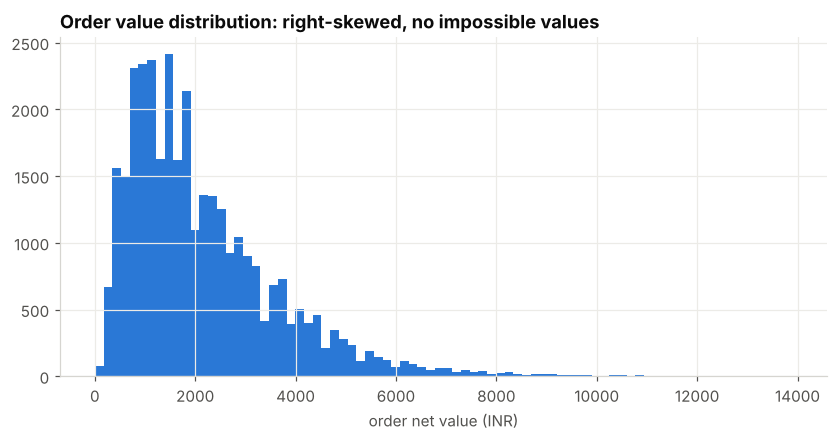

Text(0.0, 1.0, 'Order value distribution: right-skewed, no impossible values')

In [21]:
ot = q("""
select o.order_id, sum(quantity * unit_price - discount_amount) as items_net
from (select distinct * from raw.orders) o join raw.order_items i using (order_id)
join raw.users u using (user_id) where u.email_domain <> 'threadline.in' group by 1
""")
print(ot.items_net.describe(percentiles=[.01, .5, .9, .99, .999]).round(0))
fig, ax = plt.subplots()
ax.hist(ot.items_net, bins=80, color=viz.BLUE); ax.set_xlabel("order net value (INR)"); ax.set_title("Order value distribution: right-skewed, no impossible values")

**Findings:** there are no negative prices or quantities. Order values are right-skewed: the mean sits
well above the median, so **AOV is reported alongside the median**. About 0.3% of lines are
100%-discounted free gifts. These are legitimate and kept, and they contribute ₹0 revenue but carry
product cost.

## 8. Referential integrity

In [22]:
q("""
select
  (select count(*) from raw.order_items i left join raw.orders o using (order_id) where o.order_id is null) as items_without_order,
  (select count(*) from raw.order_items i left join raw.products p using (product_id) where p.product_id is null) as items_without_product,
  (select count(*) from (select distinct order_id, user_id from raw.orders) o left join raw.users u using (user_id) where u.user_id is null) as orders_without_user,
  (select count(distinct e.order_id) from raw.events e left join raw.orders o using (order_id) where e.order_id is not null and o.order_id is null) as purchase_events_without_order
""")

,items_without_order,items_without_product,orders_without_user,purchase_events_without_order
0,0,0,0,0


## 9. Tracking completeness: orders vs purchase events

In [23]:
q("""
with o as (select distinct o.order_id, o.created_at from raw.orders o join raw.users u using (user_id)
           where u.email_domain <> 'threadline.in'),
     p as (select distinct order_id from raw.events where event_name = 'purchase')
select count(*) as orders,
       sum((p.order_id is null)::int) as orders_without_purchase_event,
       round(100.0 * avg((p.order_id is null)::int), 1) as pct_untracked
from o left join p using (order_id)
""")

,orders,orders_without_purchase_event,pct_untracked
0,33499,1468,4.4


**Finding:** 4.4% of real orders have no purchase event: their whole web session never reached the
analytics collector (ad blockers or cookie consent). This is a known limitation of client-side tracking.

**Why it matters:**
1. Funnel conversion measured from events is **understated** by roughly this amount.
2. These orders cannot be linked to a session, so their channel attribution depends on the customer's
   earlier tracked visits.

**Decision:** the order system is the source of truth for **orders and revenue**, and the events are the
source of truth for **funnel rates**. The tracking gap is reported as a reconciliation metric. A customer
with no tracked session before their first order is labelled `Unattributed` rather than silently
assigned to Direct.

## 10. Funnel event consistency

In [24]:
q("""
with s as (
  select session_id,
         max((event_name = 'product_view')::int) as pv, max((event_name = 'add_to_cart')::int) as atc,
         max((event_name = 'begin_checkout')::int) as co, max((event_name = 'purchase')::int) as buy
  from raw.events group by 1)
select
  sum(buy) as purchase_sessions,
  sum((buy = 1 and atc = 0)::int) as purchase_without_cart,
  round(100.0 * sum((buy = 1 and atc = 0)::int) / sum(buy), 1) as pct_purchase_without_cart,
  sum((buy = 1 and co = 0)::int) as purchase_without_checkout,
  sum((co = 1 and atc = 0)::int) as checkout_without_cart,
  sum((atc = 1 and pv = 0)::int) as cart_without_product_view
from s
""")

,purchase_sessions,purchase_without_cart,pct_purchase_without_cart,purchase_without_checkout,checkout_without_cart,cart_without_product_view
0,32031,1602,5.0,0,1602,0


In [25]:
q("""
select page_path, count(*) as events from raw.events
where event_name = 'purchase' group by 1
""")

,page_path,events
0,/order-confirmation,32182


**Finding:** about 5% of purchasing sessions have no `add_to_cart` event but do have a product view,
checkout and purchase. This is the **"Buy Now" button**, which skips the cart. It is a legitimate path,
not a tracking error.

**Decision:** define funnel stages as **"reached this stage or any later stage"**. A Buy Now purchase
then counts as having passed the cart stage, which keeps the funnel monotonic (each stage ≤ the
previous one) without discarding real orders.

## 11. Marketing spend

In [26]:
q("""
select platform, currency, count(*) as rows_, round(sum(spend), 0) as spend, min(date) as first_date, max(date) as last_date
from raw.marketing_spend group by 1, 2 order by 1, 2
""")

,platform,currency,rows_,spend,first_date,last_date
0,affiliate_network,INR,33,338437,2024-01-31,2026-09-30
1,email_platform,INR,33,825000,2024-01-01,2026-09-01
2,google_ads,INR,3012,3859851,2024-01-01,2026-09-30
3,meta_ads,INR,1994,6089965,2024-01-01,2026-09-30
4,meta_ads,USD,14,247,2025-02-10,2025-02-16


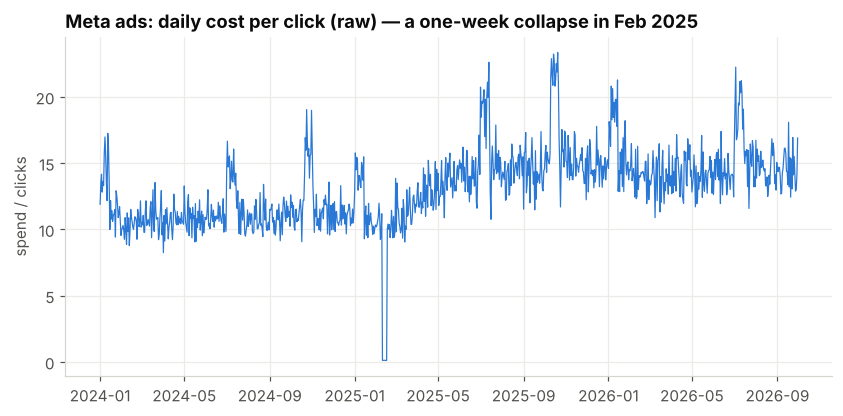

Text(29.485514322916675, 0.5, 'spend / clicks')

In [27]:
ms = q("""
select date, sum(spend) as spend, sum(clicks) as clicks, sum(spend) / sum(clicks) as cpc
from raw.marketing_spend where platform = 'meta_ads' group by 1 order by 1
""")
fig, ax = plt.subplots()
ax.plot(ms.date, ms.cpc, lw=0.8, color=viz.BLUE)
ax.set_title("Meta ads: daily cost per click (raw) — a one-week collapse in Feb 2025"); ax.set_ylabel("spend / clicks")

**Finding:** one week of Meta spend (10–16 Feb 2025) is recorded in **USD**, not INR. Its CPC drops to
about 1/87 of normal, which is impossible. If summed naively, that week's spend would be understated
about 87× and paid social CAC would look artificially good.

**Decision:** convert to INR at ₹87.0 per USD (approximate Feb-2025 rate, documented as an assumption).

Also note: **organic search, direct, referral and organic social have no media spend**. Their CAC is
not zero, because SEO, content and brand have real costs, but those costs are not in this data. CAC is
therefore only computed for paid channels.

## 12. Summary of issues → decisions

| # | Issue | Impact if ignored | Decision (implemented in) |
|---|---|---|---|
| 1 | Duplicate events (same id and re-sent) | Inflated funnel counts | Dedupe on id, then on natural key (`stg_events`) |
| 2 | Duplicate order rows | Revenue double-counted | Dedupe on `order_id` (`stg_orders`) |
| 3 | Events in UTC, orders in IST | Orders land in the wrong day or month | Convert events to IST (`stg_events`) |
| 4 | Future-dated events (clock skew) | Phantom future activity | Exclude (`stg_events`) |
| 5 | Bot sessions | Deflated conversion rates | Behavioural bot flag; exclude (`stg_sessions`) |
| 6 | No channel field; messy UTMs | Wrong channel performance | Ordered channel rules (`stg_sessions`) |
| 7 | Anonymous events | Can't attribute acquisition | Visitor→user stitching (`int_identity_map`) |
| 8 | Internal QA orders | Fake customers and orders | Exclude `threadline.in` (`stg_users`, `stg_orders`) |
| 9 | Status casing | Split categories | `lower()` (`stg_orders`) |
| 10 | `order_total` mismatch | Revenue inconsistency | Revenue from line items (`fct_orders`) |
| 11 | Untracked orders (4.4%) | Funnel understated; attribution gaps | Orders = revenue truth; `Unattributed` label |
| 12 | Buy Now skips cart | Non-monotonic funnel | "Reached stage or later" logic (`fct_sessions`) |
| 13 | USD spend rows | CAC understated | Convert at documented rate (`stg_marketing_spend`) |
| 14 | Orders in flight at snapshot | Returns not yet known | Flag; LTV uses matured windows only |